# 03. Soil moisture, runoff, river discharge, terrain, land cover and population

**Goal:** build the physical and static county columns: how wet the ground is, how high the rivers run, and what each county looks like (terrain, land cover, rivers, people).

| source | raw file | columns we build |
|---|---|---|
| ERA5-Land soil moisture and runoff | `data/raw/earth_engine/era5land_soil_runoff_county_month_cod.csv` | `soil_moisture_l1`, `soil_moisture_l2` (+ `_lag1`), `runoff_rank` |
| GloFAS river discharge | `data/raw/glofas/glofas_kenya_<year>.nc` (daily grids) | `discharge_rank`, `discharge_rank_lag1` |
| SRTM terrain | `srtm_elevation_slope_county_cod.csv` | `elevation`, `elev_std`, `slope`, `pct_flat` |
| WorldCover land cover | `worldcover_landcover_county_cod.csv` | `area_km2`, `lc_tree` ... `lc_mangrove` |
| Rivers and water | `proximity_rivers_water_county_cod.csv` | `pct_within_1km_river`, `pct_within_5km_river`, `pct_within_1km_water`, `pct_water`, `pct_occasional_water` |
| KNBS population | `data/raw/population/county_year_population.csv` | `pop_density` |
| GHSL built-up share | `ghsl_builtup_county_5yr_cod.csv` | `pct_built` (monthly) |

**Inputs:** the raw files above, `data/interim/nb_grid.csv` (notebook 01) and `nb_rain_ndvi_climate.csv` (notebook 02, only for one rainfall comparison). The pipeline files `era5land.csv`, `glofas_county_month_max.csv`, `glofas.csv`, `static_county.csv` and `slow_county_month.csv` in `data/interim/` are used to cross-check our results. The GloFAS monthly maximum per county is read from `glofas_county_month_max.csv`, because building it from the 27 daily files takes a spatial join over millions of cells (we do it for one county and one month to show the idea).

**Outputs:**
- `data/interim/nb_soil_rivers.csv`: county-month columns (soil, runoff, discharge, `pct_built`), keyed by `pcode, year, month`.
- `data/interim/nb_static_county.csv`: one row per county, keyed by `pcode`.

The reference is `src/data/06_era5land.py`, `07_static.py`, `08_glofas.py` and `common.py`.

In [1]:
# import the libraries
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xarray as xr
import shapely
from shapely.geometry import shape

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [2]:
# load the grid made in notebook 01
grid = pd.read_csv("../../data/interim/nb_grid.csv", dtype={"pcode": str})
print(grid.shape)

(14664, 7)


**Observation:** The grid from notebook 01 has 14,664 rows (47 counties x 312 months) and 7 columns.

## 1. ERA5-Land: soil moisture and runoff

ERA5-Land is a weather reanalysis from ECMWF: a model of the land that is constrained by observations. Google Earth Engine averaged it over each county for every month. We use three variables:
- `volumetric_soil_water_layer_1`: water in the top 7 cm of soil, as a fraction of the soil volume (m3 of water per m3 of soil).
- `volumetric_soil_water_layer_2`: the same for 7 to 28 cm depth.
- `runoff_sum`: runoff in the month, in metres of water over the county.

### 1.1 What the raw file looks like

In [3]:
# load the ERA5-Land soil moisture and runoff file
era = pd.read_csv("../../data/raw/earth_engine/era5land_soil_runoff_county_month_cod.csv", dtype={"pcode": str})
era = era[["pcode", "county", "year", "month", "volumetric_soil_water_layer_1", "volumetric_soil_water_layer_2", "runoff_sum"]]
print(era.shape)
era.head(3)

(14805, 7)


,pcode,county,year,month,volumetric_soil_water_layer_1,volumetric_soil_water_layer_2,runoff_sum
0,KE001,Mombasa,1999,10,0.179526,0.167141,0.002550
1,KE002,Kwale,1999,10,0.185640,0.172459,0.000603
2,KE003,Kilifi,1999,10,0.128165,0.120977,0.000153


**Observation:** The raw file has 14,805 rows. Each row is one county and one month, for example Mombasa in October 1999: top-layer soil water 0.1795, second layer 0.1671 (both as a fraction of soil volume) and a runoff sum of 0.00255 m (2.55 mm).

In [4]:
# size, period, duplicates and missing values
print("counties:", era["pcode"].nunique())
sorted_ym = era.sort_values(["year", "month"])[["year", "month"]]
print("first and last month:", sorted_ym.iloc[0].tolist(), sorted_ym.iloc[-1].tolist())
print("months per county (min, max):", era.groupby("pcode").size().min(), era.groupby("pcode").size().max())
print("47 counties x 315 months =", 47 * 315)
print("duplicate keys:", era.duplicated(["pcode", "year", "month"]).sum())
print("missing values:", era.isna().sum().sum())

counties: 47
first and last month: [1999, 10] [2025, 12]
months per county (min, max): 315 315
47 counties x 315 months = 14805
duplicate keys: 0
missing values: 0


**Observation:** There are 47 counties with 315 months each (October 1999 to December 2025), which gives 14,805 rows, with no duplicate keys and no missing values. The file starts in October 1999 so that lags and the runoff rank are available from January 2000.

In [5]:
# value ranges of the three variables
era[["volumetric_soil_water_layer_1", "volumetric_soil_water_layer_2", "runoff_sum"]].describe().round(4)

,volumetric_soil_water_layer_1,volumetric_soil_water_layer_2,runoff_sum
count,14805.0000,14805.0000,14805.0000
mean,0.2741,0.2827,0.0349
std,0.1088,0.0986,0.0694
min,0.0299,0.0961,0.0000
25%,0.1826,0.1971,0.0006
50%,0.2790,0.2805,0.0091
75%,0.3689,0.3673,0.0365
max,0.4735,0.4852,1.0718


**Observation:** Soil water is a fraction of volume: layer 1 averages 0.274 (range 0.030 to 0.474) and layer 2 averages 0.283 (0.096 to 0.485), so both stay in a believable range. Runoff is very skewed: the median is 0.0091 m, the 75th percentile 0.0365 m, but the maximum is 1.0718 m (about 1,072 mm in one month).

### 1.2 Soil moisture and its 1-month lag

In [6]:
# rename the soil columns and sort every county in time order
era = era.rename(columns={"volumetric_soil_water_layer_1": "soil_moisture_l1", "volumetric_soil_water_layer_2": "soil_moisture_l2"})
era = era.sort_values(["pcode", "year", "month"]).reset_index(drop=True)

# check that the months of every county are consecutive
t = era["year"] * 12 + era["month"] - 1
steps = t.groupby(era["pcode"]).diff().dropna()
print("every step is exactly 1 month:", (steps == 1).all())

every step is exactly 1 month: True


**Observation:** Every step between consecutive months of a county is exactly 1 month, so shifting by one row is shifting by one month.

In [7]:
# lag 1 of both soil layers (the value of the month before, within the same county)
era["soil_moisture_l1_lag1"] = era.groupby("pcode")["soil_moisture_l1"].shift(1)
era["soil_moisture_l2_lag1"] = era.groupby("pcode")["soil_moisture_l2"].shift(1)

# look at Kisumu around April 2024
era[(era["pcode"] == "KE042") & (era["year"] == 2024) & (era["month"].between(2, 4))][["year", "month", "soil_moisture_l1", "soil_moisture_l1_lag1", "soil_moisture_l2", "soil_moisture_l2_lag1"]]

,year,month,soil_moisture_l1,soil_moisture_l1_lag1,soil_moisture_l2,soil_moisture_l2_lag1
13207,2024,2,0.320800,0.391183,0.329588,0.391320
13208,2024,3,0.291607,0.320800,0.295481,0.329588
13209,2024,4,0.409959,0.291607,0.412748,0.295481


**Observation:** For Kisumu the lag columns hold the month before: April 2024 `soil_moisture_l1` is 0.4100 and its lag is 0.2916, which is the March value. The top layer jumped by 0.12 in one month, from 0.29 to 0.41, after the April 2024 rains. The second layer did the same (0.2955 to 0.4127).

### 1.3 Why the raw runoff cannot be used directly

ERA5-Land runoff comes from a land model, not from gauges. Before using it we compare it with the CHIRPS rainfall we built in notebook 02. Runoff should be a fraction of the rain that fell. We put both in millimetres.

In [8]:
# load the CHIRPS rainfall of notebook 02 and join it to the ERA5 months
rain = pd.read_csv("../../data/interim/nb_rain_ndvi_climate.csv", dtype={"pcode": str}, usecols=["pcode", "year", "month", "rain_mm"])
cmp = era.merge(rain, on=["pcode", "year", "month"], how="inner")
cmp["runoff_mm"] = cmp["runoff_sum"] * 1000
print("months compared:", len(cmp))
print("share of county-months where runoff is larger than the rain:", round((cmp["runoff_mm"] > cmp["rain_mm"]).mean(), 3))

months compared: 14664
share of county-months where runoff is larger than the rain: 0.084


**Observation:** 14,664 county-months can be compared with CHIRPS (2000-2025). In 8.4% of them the ERA5-Land runoff is larger than the rain that fell, which cannot be right for a month total.

In [9]:
# average runoff and average rain of every county, and their ratio
by_county = cmp.groupby("county")[["rain_mm", "runoff_mm"]].mean()
by_county["runoff_over_rain"] = by_county["runoff_mm"] / by_county["rain_mm"]
by_county = by_county.sort_values("runoff_over_rain")
print("ratio runoff / rain: min", by_county["runoff_over_rain"].min().round(2), "median", by_county["runoff_over_rain"].median().round(2), "max", by_county["runoff_over_rain"].max().round(2))
print("counties with a ratio above 1:", (by_county["runoff_over_rain"] > 1).sum())
pd.concat([by_county.head(4), by_county.tail(6)]).round(2)

ratio runoff / rain: min 0.01 median 0.21 max 1.84
counties with a ratio above 1: 2


,rain_mm,runoff_mm,runoff_over_rain
county,,,
Kilifi,80.25,0.96,0.01
Tana River,39.08,0.50,0.01
Garissa,43.51,0.60,0.01
Marsabit,27.98,0.47,0.02
Kericho,138.23,79.93,0.58
Bungoma,150.03,121.86,0.81
Uasin Gishu,114.53,107.75,0.94
Trans Nzoia,120.22,115.93,0.96
West Pokot,78.38,99.04,1.26


**Observation:** The ratio of average runoff to average rain goes from 0.01 to 1.84, with a median of 0.21. The very dry counties turn almost none of their rain into runoff (Kilifi 0.96 mm of 80 mm, Tana River 0.50 of 39 mm, Garissa, Marsabit), while Elgeyo-Marakwet has 223 mm of runoff on 121 mm of rain, and West Pokot 99 mm on 78 mm. Two counties have a ratio above 1, which is impossible on average.

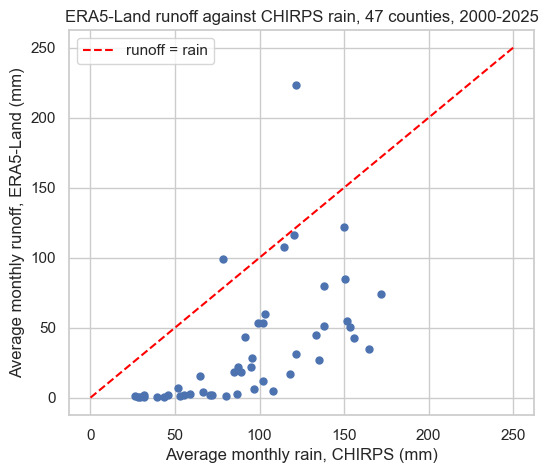

In [10]:
# plot average runoff against average rain for the 47 counties
plt.figure(figsize=(6, 5))
plt.scatter(by_county["rain_mm"], by_county["runoff_mm"], s=25)
plt.plot([0, 250], [0, 250], color="red", linestyle="--", label="runoff = rain")
plt.xlabel("Average monthly rain, CHIRPS (mm)")
plt.ylabel("Average monthly runoff, ERA5-Land (mm)")
plt.title("ERA5-Land runoff against CHIRPS rain, 47 counties, 2000-2025")
plt.legend()
plt.show()

**Observation:** Almost all counties sit well under the red line, many close to the bottom axis, and two points are above it (Elgeyo-Marakwet and West Pokot). The cloud has no clear line: at about 120 mm of rain, runoff is anywhere from about 15 mm to over 200 mm, depending on the county. Absolute runoff cannot be compared between counties.

The ERA5 *rainfall* file in `data/raw/earth_engine/era5land_precip_county_month.csv` tells the same story from the other side: is the model's own rain close to CHIRPS? It was exported on the old DesInventar polygons, so we link it to our counties with the crosswalk. It is a diagnostic only and is not used as a feature.

In [11]:
# link the ERA5 rainfall (old polygons, in metres) to pcode with the crosswalk
cw = pd.read_csv("../../data/reference/kenya_county_crosswalk.csv", dtype=str)
cw["COUNTYCO"] = cw["desinventar_code"].str.zfill(2)
era_p = pd.read_csv("../../data/raw/earth_engine/era5land_precip_county_month.csv", dtype={"COUNTYCO": str})
era_p = era_p.merge(cw[["COUNTYCO", "pcode"]], on="COUNTYCO", how="left")
era_p["era5_rain_mm"] = era_p["mean"] * 1000
print("rows:", len(era_p), "| counties linked:", era_p["pcode"].nunique(), "| unlinked rows:", era_p["pcode"].isna().sum())

rows: 14805 | counties linked: 47 | unlinked rows: 0


**Observation:** All 14,805 ERA5 rainfall rows link to a county with the crosswalk (47 counties, 0 unlinked rows).

In [12]:
# average ERA5 rain divided by average CHIRPS rain, per county, over the same months
both = era_p.merge(rain, on=["pcode", "year", "month"], how="inner")
ratio = both.groupby("pcode")[["era5_rain_mm", "rain_mm"]].mean()
ratio["era5_over_chirps"] = ratio["era5_rain_mm"] / ratio["rain_mm"]
ratio = ratio.join(cw.set_index("pcode")["county"])
print("ratio ERA5 rain / CHIRPS rain: min", ratio["era5_over_chirps"].min().round(2), "median", ratio["era5_over_chirps"].median().round(2), "max", ratio["era5_over_chirps"].max().round(2))
ratio.sort_values("era5_over_chirps").iloc[[0, 1, 2, -3, -2, -1]].round(2)

ratio ERA5 rain / CHIRPS rain: min 0.66 median 1.0 max 2.68


,era5_rain_mm,rain_mm,era5_over_chirps,county
pcode,,,,
KE003,52.57,80.25,0.66,Kilifi
KE007,29.34,43.51,0.67,Garissa
KE001,76.07,108.08,0.70,Mombasa
KE027,206.45,114.53,1.80,Uasin Gishu
KE024,178.08,78.38,2.27,West Pokot
KE028,325.04,121.32,2.68,Elgeyo-Marakwet


**Observation:** ERA5 rain over CHIRPS rain ranges from 0.66 to 2.68 with a median of 1.00. In most counties the two agree, but ERA5 has 2.7 times the CHIRPS rain in Elgeyo-Marakwet, 2.3 times in West Pokot and 1.8 times in Uasin Gishu, which are also the counties with the highest runoff/rain ratios. So the runoff problem seems linked to ERA5's own rain being too high there. This is why we only use the rank inside a county, not the raw value.

### 1.4 runoff_rank: where this month's runoff stands against the same calendar month in 2000-2019

Because the absolute runoff is not reliable, we keep only its *rank inside the county*: for a given county and calendar month (say all Aprils of Kisumu), how does this month compare with the same month in the 20 baseline years 2000-2019?

`runoff_rank` is the mid-rank percentile: the share of baseline values below this value, plus half the share equal to it. It goes from 0 (lowest ever) to 1 (highest ever). Equal values (if there are any, for example many months with exactly 0 runoff in a dry county) all get the middle of their block, instead of the lowest or the highest rank.

A tiny example with 5 baseline values:

In [13]:
# tiny example of the mid-rank percentile
base = np.array([0, 0, 2, 5, 9])
example = pd.DataFrame({"value": [0, 2, 7, 12]})
example["below"] = [(base < v).sum() for v in example["value"]]
example["equal"] = [(base == v).sum() for v in example["value"]]
example["rank"] = (example["below"] + example["equal"] / 2) / len(base)
print("baseline values:", base.tolist())
example

baseline values: [0, 0, 2, 5, 9]


,value,below,equal,rank
0,0,0,2,0.2
1,2,2,1,0.5
2,7,4,0,0.8
3,12,5,0,1.0


**Observation:** With the baseline [0, 0, 2, 5, 9]: the value 0 has none below and 2 equal, so its rank is (0 + 1) / 5 = 0.2, the middle of its block. The value 2 gets 0.5, a value of 7 gets 0.8 (4 of 5 below), and 12, higher than every baseline value, gets 1.0.

In [14]:
# compute runoff_rank for every county, calendar month and year
era["runoff_rank"] = np.nan
for (pc, mo), g in era.groupby(["pcode", "month"]):
    base = g.loc[g["year"].between(2000, 2019), "runoff_sum"].to_numpy()
    x = g["runoff_sum"].to_numpy()
    below = (base[None, :] < x[:, None]).sum(axis=1)
    equal = (base[None, :] == x[:, None]).sum(axis=1)
    era.loc[g.index, "runoff_rank"] = (below + equal / 2) / len(base)
print("runoff_rank min and max:", era["runoff_rank"].min(), era["runoff_rank"].max())
print("missing:", era["runoff_rank"].isna().sum())

runoff_rank min and max: 0.0 1.0
missing: 0


**Observation:** `runoff_rank` has no missing values and spans 0.0 to 1.0, so the loop over 564 county + calendar-month groups covered all 14,805 rows, including October to December 1999.

In [15]:
# worked example: Kisumu April 2024 against the 20 Aprils of 2000-2019
k = era[(era["pcode"] == "KE042") & (era["month"] == 4)]
k_base = k[k["year"].between(2000, 2019)]["runoff_sum"]
k_2024 = k[k["year"] == 2024]["runoff_sum"].iloc[0]
print("Kisumu April 2024 runoff:", round(k_2024 * 1000, 2), "mm")
print("Aprils 2000-2019 with less runoff:", (k_base < k_2024).sum(), "of", len(k_base))
print("runoff_rank in the table:", k[k["year"] == 2024]["runoff_rank"].iloc[0])

Kisumu April 2024 runoff: 145.99 mm
Aprils 2000-2019 with less runoff: 20 of 20
runoff_rank in the table: 1.0


**Observation:** Kisumu in April 2024 had 145.99 mm of runoff, more than all 20 Aprils of 2000-2019, so its `runoff_rank` is 1.0. It was the wettest April in the whole record for this county.

In [16]:
# check for tied runoff values inside the baseline of each county and calendar month
base_rows = era[era["year"].between(2000, 2019)]
tied = base_rows.duplicated(["pcode", "month", "runoff_sum"], keep=False)
print("baseline values tied with another value:", tied.sum(), "of", len(base_rows))
print("smallest runoff_sum in the file (m):", era["runoff_sum"].min())
print("rank of the smallest runoff in each of the 47 counties (min, max):", era.loc[era.groupby("pcode")["runoff_sum"].idxmin(), "runoff_rank"].min().round(3), era.loc[era.groupby("pcode")["runoff_sum"].idxmin(), "runoff_rank"].max().round(3))

baseline values tied with another value: 0 of 11280
smallest runoff_sum in the file (m): 7.292780129382374e-07
rank of the smallest runoff in each of the 47 counties (min, max): 0.0 0.025


**Observation:** In the baseline years no value is tied with another one (0 of 11,280 baseline rows) and the smallest runoff in the file is 7.3e-07 m, so no county-month has exactly 0 runoff. The mid-rank rule for ties is therefore not needed for this file, but it is kept so the rank stays fair for a file with zeros. The lowest-runoff month of each county has a rank between 0.0 and 0.025.

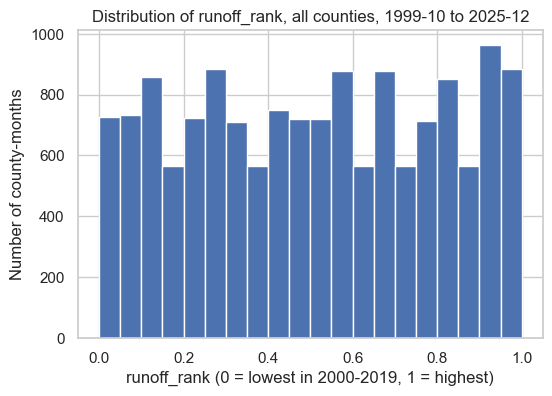

In [17]:
# plot the distribution of runoff_rank
plt.figure(figsize=(6, 4))
plt.hist(era["runoff_rank"], bins=20, edgecolor="white")
plt.xlabel("runoff_rank (0 = lowest in 2000-2019, 1 = highest)")
plt.ylabel("Number of county-months")
plt.title("Distribution of runoff_rank, all counties, 1999-10 to 2025-12")
plt.show()

**Observation:** The ranks are spread over the whole range from 0 to 1, with 560 to 960 county-months per bar and no big spike at one end, as expected for percentiles. The bars are not perfectly flat because there are only 20 baseline values per county and month, so only 20 different rank values exist.

### 1.5 Keep the grid months and check against the pipeline

In [18]:
# keep 2000-2025 and the five ERA5 columns
era_cols = ["soil_moisture_l1", "soil_moisture_l1_lag1", "soil_moisture_l2", "soil_moisture_l2_lag1", "runoff_rank"]
era_out = era[era["year"] >= 2000][["pcode", "year", "month"] + era_cols].reset_index(drop=True)
print(era_out.shape)
print("duplicate keys:", era_out.duplicated(["pcode", "year", "month"]).sum())
print("missing values per column:")
print(era_out[era_cols].isna().sum().to_dict())

(14664, 8)
duplicate keys: 0
missing values per column:
{'soil_moisture_l1': 0, 'soil_moisture_l1_lag1': 0, 'soil_moisture_l2': 0, 'soil_moisture_l2_lag1': 0, 'runoff_rank': 0}


**Observation:** After keeping 2000-2025 the table has 14,664 rows and 8 columns (3 keys and 5 features), with no duplicate keys and 0 missing values in the five columns.

In [19]:
# compare with the pipeline's data/interim/era5land.csv
pipe = pd.read_csv("../../data/interim/era5land.csv", dtype={"pcode": str})
both = era_out.merge(pipe, on=["pcode", "year", "month"], suffixes=("", "_pipe"), how="outer", indicator=True)
print("rows matched:", (both["_merge"] == "both").sum(), "of", len(both))
for c in era_cols:
    print(c, "largest difference:", (both[c] - both[c + "_pipe"]).abs().max())

rows matched:

 14664 of 14664
soil_moisture_l1 largest difference: 0.0
soil_moisture_l1_lag1 largest difference: 0.0
soil_moisture_l2 largest difference: 0.0
soil_moisture_l2_lag1 largest difference: 0.0
runoff_rank largest difference: 0.0


**Observation:** All 14,664 rows match the pipeline's `era5land.csv` and the largest difference is 0.0 in all five columns.

## 2. GloFAS river discharge

GloFAS is the Global Flood Awareness System of the European Commission and ECMWF. It simulates river flow everywhere on a 0.05 degree grid (about 5 km) and gives one value per day. The value is the average discharge of the 24 hours, in cubic metres of water per second (m3/s). We downloaded one NetCDF file per year, 1999-2025 (27 files, about 240 MB, not in git).

### 2.1 Open one year

In [20]:
# open the file of 2024 and look at its structure
ds = xr.open_dataset("../../data/raw/glofas/glofas_kenya_2024.nc")
print(ds)

<xarray.Dataset> Size: 58MB
Dimensions:     (valid_time: 365, latitude: 220, longitude: 180)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 3kB 2024-01-02 ... 2024-12-31
  * latitude    (latitude) float64 2kB 5.475 5.425 5.375 ... -5.425 -5.475
  * longitude   (longitude) float64 1kB 33.52 33.57 33.62 ... 42.37 42.42 42.48
    surface     float64 8B ...
Data variables:
    avg_dis     (valid_time, latitude, longitude) float32 58MB ...
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts


**Observation:** The file of 2024 holds one variable `avg_dis` with three dimensions: 365 days (`valid_time`), 220 latitudes and 180 longitudes. It is a 58 MB array for one year. Longitude and latitude have a step of 0.05 degrees.

In [21]:
# the variable, its unit, the grid size and the days
q = ds["avg_dis"].squeeze(drop=True)
print("variable dims:", q.dims)
print("units:", ds["avg_dis"].attrs.get("units"))
print("grid step (degrees):", round(float(ds["latitude"].values[0] - ds["latitude"].values[1]), 3))
print("number of cells:", q.shape[1] * q.shape[2])
print("days in the file:", q.shape[0], "(2024 is a leap year with 366 days)")
print("discharge min and max over the year (m3/s):", round(float(q.min()), 2), round(float(q.max()), 1))

variable dims: ('valid_time', 'latitude', 'longitude')
units: m**3 s**-1
grid step (degrees): 0.05
number of cells: 39600
days in the file: 365 (2024 is a leap year with 366 days)
discharge min and max over the year (m3/s): 0.0 4803.0


**Observation:** The unit is m3/s (`m**3 s**-1`). The grid has 220 x 180 = 39,600 cells of 0.05 degrees (about 5.5 km). The file has 365 days, one less than the 366 days of a leap year. Discharge goes from 0.0 to 4,803.0 m3/s in the year, which shows that cells of big rivers and cells of dry land share one grid.

### 2.2 The date stamp: valid_time is the END of the 24 hours

Each daily value is stamped with the *end* of its 24-hour window, so `valid_time` = 2024-01-02 holds the average of 1 January. The real date is `valid_time` minus one day. If we forgot this, the values of 1 April would be counted in March and the last day of each month would fall in the next one.

In [22]:
# real date of each daily value
real_date = pd.DatetimeIndex(ds["valid_time"].values) - pd.Timedelta(days=1)
dates = pd.DataFrame({"valid_time": ds["valid_time"].values, "real_date": real_date})
print("first and last valid_time:", dates["valid_time"].iloc[0].date(), dates["valid_time"].iloc[-1].date())
print("first and last real date :", dates["real_date"].iloc[0].date(), dates["real_date"].iloc[-1].date())
missing_days = sorted(set(pd.date_range("2024-01-01", "2024-12-31")) - set(real_date))
print("real dates in 2024 that are missing:", [str(d.date()) for d in missing_days])

first and last valid_time: 2024-01-02 2024-12-31
first and last real date : 2024-01-01 2024-12-30
real dates in 2024 that are missing: ['2024-12-31']


**Observation:** The first `valid_time` is 2 January 2024 and the first real date is 1 January 2024. The last real date is 30 December 2024, so the real date 31 December 2024 is missing. This is the one known gap of the source (ECMWF has no data for the request of 31 December 2024), so December 2024 is a mean over 30 days.

### 2.3 One value per county: the largest cell inside the county

A county contains many 5 km cells (from 8 to over 2,000), but a flood comes from the river, which passes through only a few of them. The average over all cells would hide the river, so the pipeline keeps the **maximum monthly-mean cell whose centre lies inside the county polygon**. Here is the full path for Kisumu in April 2024.

In [23]:
# load the land-only county polygon of Kisumu
gj = json.load(open("../../data/reference/kenya_counties.geojson", encoding="utf-8"))
kisumu_poly = [shape(f["geometry"]) for f in gj["features"] if f["properties"]["pcode"] == "KE042"][0]
kisumu_poly = shapely.make_valid(kisumu_poly)
print("polygon area in square degrees:", round(kisumu_poly.area, 4))

polygon area in square degrees: 0.1691


**Observation:** The land-only polygon of Kisumu covers 0.1691 square degrees, about 2,090 km2 without the lake, so it is small compared with the 0.05 x 0.05 degree cells (0.0025 square degrees each).

In [24]:
# find the grid cells whose centre lies inside the polygon
lon2, lat2 = np.meshgrid(ds["longitude"].values, ds["latitude"].values)
inside = shapely.contains_xy(kisumu_poly, lon2.ravel(), lat2.ravel()).reshape(lon2.shape)
print("cells inside Kisumu:", inside.sum(), "of", inside.size)

cells inside Kisumu: 68 of 39600


**Observation:** 68 of the 39,600 grid cells have their centre inside Kisumu county.

In [25]:
# monthly mean of every cell in April 2024, using the REAL date
april = (real_date.year == 2024) & (real_date.month == 4)
cells_april = q.values[april][:, inside].astype("float64")
cell_mean = cells_april.mean(axis=0)
print("days in April:", april.sum())
print("mean over the 68 cells:", round(cell_mean.mean(), 2), "m3/s")
print("median cell:", round(np.median(cell_mean), 2), "m3/s")
print("largest cell:", round(cell_mean.max(), 2), "m3/s")

days in April: 30
mean over the 68 cells: 33.01 m3/s
median cell: 3.1 m3/s
largest cell: 276.16 m3/s


**Observation:** April 2024 has 30 days. Over the 68 cells the mean discharge is 33.0 m3/s and the median cell only 3.1 m3/s, but the largest cell is 276.2 m3/s. Most cells are land with no river, and one cell on the main river carries 8 times the mean. A mean over the county would hide the river, which is why the maximum is used.

In [26]:
# what would happen if we used valid_time instead of the real date
wrong = (ds["valid_time"].dt.month == 4).values
wrong_max = q.values[wrong][:, inside].astype("float64").mean(axis=0).max()
print("largest cell with valid_time:", round(wrong_max, 2), "m3/s")
print("largest cell with the real date:", round(cell_mean.max(), 2), "m3/s")

largest cell with valid_time: 267.32 m3/s
largest cell with the real date: 276.16 m3/s


**Observation:** With `valid_time` instead of the real date the largest cell is 267.3 m3/s instead of 276.2 m3/s. The 3% difference comes from a shifted 24-hour window (the days 31 March to 29 April instead of 1 to 30 April). The shift is small for one month, but one day would be moved to the wrong month at every month boundary.

### 2.4 The monthly maximum per county from the pipeline

In [27]:
# load the monthly maximum per county made by the pipeline from the 27 files
gmax = pd.read_csv("../../data/interim/glofas_county_month_max.csv", dtype={"pcode": str})
print(gmax.shape)
gm_ym = gmax.sort_values(["year", "month"])[["year", "month"]]
print("period:", gm_ym.iloc[0].tolist(), "to", gm_ym.iloc[-1].tolist())
print("counties:", gmax["pcode"].nunique(), "| missing discharge_max_cell:", gmax["discharge_max_cell"].isna().sum())
print("cells inside a county (min, max):", gmax["n_cells"].min(), gmax["n_cells"].max())
gmax[["pcode", "year", "month", "discharge_max_cell", "n_cells"]].head(3)

(15228, 7)
period: [1999, 1] to [2025, 12]
counties: 47 | missing discharge_max_cell: 0
cells inside a county (min, max): 8 2314


,pcode,year,month,discharge_max_cell,n_cells
0,KE001,1999,1,1.167339,8
1,KE001,1999,2,0.943080,8
2,KE001,1999,3,1.045363,8


**Observation:** The pipeline file has 15,228 rows (47 counties x 324 months, January 1999 to December 2025) with no missing `discharge_max_cell`. The number of cells per county goes from 8 to 2,314. The first rows are Mombasa in 1999 with values of about 1 m3/s.

In [28]:
# check our Kisumu April 2024 value against this file
pipe_k = gmax[(gmax["pcode"] == "KE042") & (gmax["year"] == 2024) & (gmax["month"] == 4)]
print("pipeline discharge_max_cell:", round(pipe_k["discharge_max_cell"].iloc[0], 4))
print("our value from section 2.3 :", round(cell_mean.max(), 4))
print("pipeline n_cells:", pipe_k["n_cells"].iloc[0])

pipeline discharge_max_cell: 276.1552
our value from section 2.3 : 276.1552
pipeline n_cells: 68


**Observation:** Our own calculation gives 276.1552 m3/s for Kisumu in April 2024, with 68 cells, exactly the value of the pipeline file, so we can trust the pipeline's file for the other counties and months.

### 2.5 discharge_rank and its 1-month lag

Discharge in m3/s cannot be compared between a small stream and the Tana River, so we use the same mid-rank percentile as for runoff: this county, this calendar month, against 2000-2019. One extra rule: a county and month needs at least 15 of the 20 baseline years, otherwise the rank stays blank, since a rank among 1 to 3 years is meaningless.

In [29]:
# compute discharge_rank (mid-rank percentile against 2000-2019, at least 15 baseline years)
gmax = gmax.sort_values(["pcode", "year", "month"]).reset_index(drop=True)
gmax["discharge_rank"] = np.nan
n_short = 0
for (pc, mo), g in gmax.groupby(["pcode", "month"]):
    base = g.loc[g["year"].between(2000, 2019), "discharge_max_cell"].dropna().to_numpy()
    if len(base) < 15:
        n_short += 1
        continue
    x = g["discharge_max_cell"].to_numpy()
    below = (base[None, :] < x[:, None]).sum(axis=1)
    equal = (base[None, :] == x[:, None]).sum(axis=1)
    gmax.loc[g.index, "discharge_rank"] = (below + equal / 2) / len(base)
print("county + calendar months with fewer than 15 baseline years:", n_short, "of", 47 * 12)
print("missing discharge_rank:", gmax["discharge_rank"].isna().sum())

county + calendar months with fewer than 15 baseline years: 0 of 564
missing discharge_rank: 0


**Observation:** All 564 county + calendar-month groups have at least 15 of the 20 baseline years, so no `discharge_rank` is blank (0 missing among 15,228 rows). The 15-year rule is a safety rule that does not remove anything here.

In [30]:
# lag 1 on the full series (the 1999 months give the lag for January 2000)
t = gmax["year"] * 12 + gmax["month"] - 1
steps = t.groupby(gmax["pcode"]).diff().dropna()
print("every step is exactly 1 month:", (steps == 1).all())
gmax["discharge_rank_lag1"] = gmax.groupby("pcode")["discharge_rank"].shift(1)

# Kisumu around April 2024
gmax[(gmax["pcode"] == "KE042") & (gmax["year"] == 2024) & (gmax["month"].between(2, 5))][["year", "month", "discharge_max_cell", "discharge_rank", "discharge_rank_lag1"]]

every step is exactly 1 month: True


,year,month,discharge_max_cell,discharge_rank,discharge_rank_lag1
13585,2024,2,120.577586,0.95,0.90
13586,2024,3,70.868952,0.90,0.95
13587,2024,4,276.155208,1.00,0.90
13588,2024,5,307.614415,0.95,1.00


**Observation:** Kisumu's discharge in April 2024 was 276.2 m3/s, above all 20 Aprils of 2000-2019, so the rank is 1.00. In May the flow was higher, 307.6 m3/s, but its rank is 0.95 because the May baseline is higher too (19 of the 20 baseline Mays are below). The lag column holds the previous month's rank (April 2024 has 0.90, the March rank). The ranks move in steps of 0.05, since 20 baseline years only give 20 distinct values.

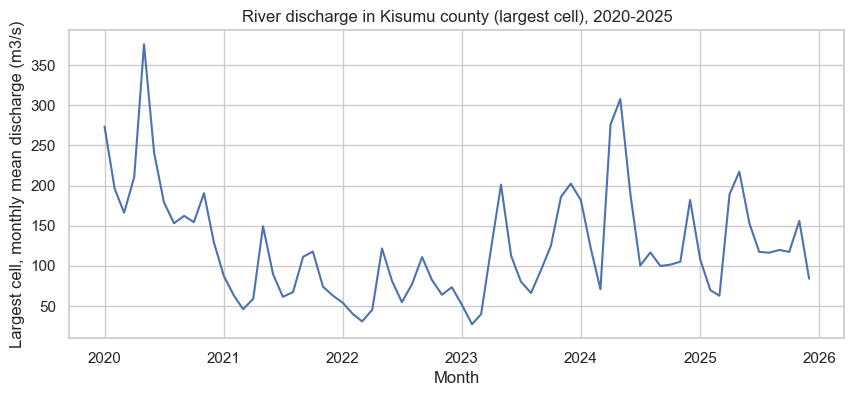

In [31]:
# plot the monthly maximum cell of Kisumu from 2020 to 2025
kk = gmax[(gmax["pcode"] == "KE042") & (gmax["year"] >= 2020)].copy()
kk["date"] = pd.to_datetime(dict(year=kk["year"], month=kk["month"], day=1))
plt.figure(figsize=(10, 4))
plt.plot(kk["date"], kk["discharge_max_cell"])
plt.xlabel("Month")
plt.ylabel("Largest cell, monthly mean discharge (m3/s)")
plt.title("River discharge in Kisumu county (largest cell), 2020-2025")
plt.show()

**Observation:** Kisumu's river cell has a seasonal pattern with peaks in April-May, and two very different years: the peak of about 375 m3/s in spring 2020, then the low flows of 2021-2022 (never above about 150 m3/s), then a new high of about 308 m3/s in May 2024 after the heavy April-May rains. The rains of 2025 gave a smaller peak (about 217 m3/s).

In [32]:
# keep the grid months and compare with the pipeline's data/interim/glofas.csv
glo_cols = ["discharge_rank", "discharge_rank_lag1"]
glo_out = grid[["pcode", "year", "month"]].merge(gmax[["pcode", "year", "month"] + glo_cols], on=["pcode", "year", "month"], how="left")
print("rows:", len(glo_out), "| missing:", glo_out[glo_cols].isna().sum().to_dict())
pipe = pd.read_csv("../../data/interim/glofas.csv", dtype={"pcode": str})
both = glo_out.merge(pipe, on=["pcode", "year", "month"], suffixes=("", "_pipe"))
print("rows matched:", len(both), "of", len(glo_out))
for c in glo_cols:
    print(c, "largest difference:", (both[c] - both[c + "_pipe"]).abs().max())

rows: 14664 | missing: {'discharge_rank': 0, 'discharge_rank_lag1': 0}
rows matched: 14664 of 14664
discharge_rank largest difference: 0.0
discharge_rank_lag1 largest difference: 0.0


**Observation:** After keeping the grid months there are 14,664 rows with no missing value in either rank column, and they match the pipeline's `glofas.csv` exactly (largest difference 0.0 for both).

## 3. Static county features

These columns do not change over time. Each county has one value, repeated on all its 312 months. All five Earth Engine files were exported on the same county polygons (OCHA COD-AB with the lakes removed) and are keyed by `pcode`.

### 3.1 Terrain (SRTM)

In [33]:
# load the terrain file and keep the four columns we use
srtm = pd.read_csv("../../data/raw/earth_engine/srtm_elevation_slope_county_cod.csv", dtype={"pcode": str})
print("columns in the file:", srtm.columns.tolist())
srtm = srtm.rename(columns={"stdDev": "elev_std"})[["pcode", "elevation", "elev_std", "slope", "pct_flat"]]
print(srtm.shape, "| duplicate pcodes:", srtm["pcode"].duplicated().sum(), "| missing:", srtm.isna().sum().sum())
srtm.describe().round(3)

columns in the file: ['system:index', 'county', 'elevation', 'max', 'min', 'pcode', 'pct_flat', 'slope', 'stdDev', '.geo']
(47, 5) | duplicate pcodes: 0 | missing: 0


,elevation,elev_std,slope,pct_flat
count,47.000,47.000,47.000,47.000
mean,1295.674,275.620,4.729,0.391
std,679.190,187.135,2.395,0.245
min,24.365,14.265,0.958,0.063
25%,673.509,137.555,2.837,0.228
50%,1365.294,224.100,4.491,0.310
75%,1874.293,351.762,6.276,0.517
max,2535.028,792.234,10.906,0.956


**Observation:** 47 counties, no duplicates and no missing values. Mean elevation goes from 24 m (coast) to 2,535 m (highlands) with a median of 1,365 m. The slope goes from 1.0 to 10.9 degrees, `pct_flat` from 0.06 to 0.96 (mean 0.39), and `elev_std` from 14 to 792 m, so counties differ a lot in how flat or rugged they are.

- `elevation`: mean height above sea level (m).
- `elev_std`: standard deviation of the height inside the county (m), a measure of how rugged it is.
- `slope`: mean slope (degrees).
- `pct_flat`: share of the county that is flat, as a fraction between 0 and 1.

### 3.2 Land cover (WorldCover)

In [34]:
# load the land-cover file; rename pct_<class> to lc_<class>
classes = ["tree", "shrub", "grass", "crop", "built", "bare", "water", "wetland", "mangrove"]
wc = pd.read_csv("../../data/raw/earth_engine/worldcover_landcover_county_cod.csv", dtype={"pcode": str})
wc = wc.rename(columns={"pct_" + c: "lc_" + c for c in classes})
wc = wc[["pcode", "area_km2"] + ["lc_" + c for c in classes]]
print(wc.shape, "| missing:", wc.isna().sum().sum())
wc.describe().round(3)

(47, 11) | missing: 0


,area_km2,lc_tree,lc_shrub,lc_grass,lc_crop,lc_built,lc_bare,lc_water,lc_wetland,lc_mangrove
count,47.000,47.000,47.000,47.000,47.000,47.000,47.000,47.000,47.000,47.000
mean,12407.915,0.245,0.360,0.234,0.120,0.021,0.011,0.007,0.003,0.001
std,17417.969,0.194,0.203,0.156,0.130,0.067,0.036,0.011,0.006,0.003
min,234.642,0.001,0.069,0.021,0.000,0.000,0.000,0.000,0.000,0.000
25%,2533.409,0.088,0.220,0.112,0.016,0.001,0.001,0.000,0.000,0.000
50%,3349.542,0.207,0.287,0.202,0.091,0.005,0.002,0.001,0.000,0.000
75%,14931.239,0.391,0.476,0.307,0.169,0.011,0.003,0.006,0.002,0.000
max,71424.706,0.692,0.953,0.635,0.519,0.331,0.195,0.051,0.027,0.019


**Observation:** 47 rows with no missing values. County area goes from 235 to 71,425 km2 (median 3,350 km2). On average a county is 36% shrub, 24.5% tree, 23.4% grass and 12% crop; built-up area averages 2.1% but reaches 33% in the most urban county. The classes `lc_wetland` (mean 0.3%) and `lc_mangrove` (0.1%) are tiny in most counties.

In [35]:
# the nine shares of a county should add up to 1 (they are fractions, not percentages)
share_sum = wc[["lc_" + c for c in classes]].sum(axis=1)
print("sum of the nine shares: min", share_sum.min().round(5), "max", share_sum.max().round(5))
print("total area of the 47 counties:", round(wc["area_km2"].sum()), "km2")

sum of the nine shares: min 0.99996 max 1.0
total area of the 47 counties: 583172 km2


**Observation:** The nine land-cover shares add up to between 0.99996 and 1.0 for every county, so they are fractions of the county (not percentages) and nothing is missing. The 47 counties together cover 583,172 km2, close to the area of Kenya.

### 3.3 Rivers and water

In [36]:
# load the proximity file and look at all its columns first
prox = pd.read_csv("../../data/raw/earth_engine/proximity_rivers_water_county_cod.csv", dtype={"pcode": str})
print(prox.columns.tolist())
prox[["river_dist_m", "water_dist_m"]].describe().round(0)

['system:index', 'county', 'pcode', 'pct_occasional_water', 'pct_water', 'pct_within_1km_river', 'pct_within_1km_water', 'pct_within_5km_river', 'river_dist_m', 'water_dist_m', '.geo']


,river_dist_m,water_dist_m
count,47.0,47.0
mean,4490.0,4465.0
std,292.0,643.0
min,3733.0,1462.0
25%,4318.0,4321.0
50%,4518.0,4657.0
75%,4733.0,4913.0
max,4975.0,5000.0


**Observation:** The file has two distance columns, the distance to a river and to water. `river_dist_m` goes only from 3,733 to 4,975 m (mean 4,490 m) and `water_dist_m` from 1,462 to 5,000 m (mean 4,465 m). Both are capped at 5 km, so they are close to 5,000 for nearly all counties.

In [37]:
# how many counties sit at (or very near) the 5 km cap of the distance columns
print("river_dist_m at least 4,900 m:", (prox["river_dist_m"] >= 4900).sum(), "of 47")
print("water_dist_m at least 4,900 m:", (prox["water_dist_m"] >= 4900).sum(), "of 47")
print("coefficient of variation (std / mean): river", (prox["river_dist_m"].std() / prox["river_dist_m"].mean()).round(3), "| water", (prox["water_dist_m"].std() / prox["water_dist_m"].mean()).round(3))

river_dist_m at least 4,900 m: 2 of 47
water_dist_m at least 4,900 m: 13 of 47
coefficient of variation (std / mean): river 0.065 | water 0.144


**Observation:** 2 counties for rivers and 13 for water are at or within 100 m of the 5,000 m cap. The relative variation is small (0.065 and 0.144), so the two columns barely separate counties. We drop them and keep the five share columns.

In [38]:
# keep the five share columns and drop the two distance columns
prox_keep = ["pct_within_1km_river", "pct_within_5km_river", "pct_within_1km_water", "pct_water", "pct_occasional_water"]
prox = prox[["pcode"] + prox_keep]
print(prox.shape, "| missing:", prox.isna().sum().sum())
prox[prox_keep].describe().round(4)

(47, 6) | missing: 0


,pct_within_1km_river,pct_within_5km_river,pct_within_1km_water,pct_water,pct_occasional_water
count,47.0000,47.0000,47.0000,47.0000,47.0000
mean,0.0420,0.2017,0.0385,0.0045,0.0004
std,0.0268,0.1081,0.0626,0.0093,0.0006
min,0.0017,0.0100,0.0000,0.0000,0.0000
25%,0.0189,0.1283,0.0072,0.0000,0.0000
50%,0.0364,0.1980,0.0213,0.0006,0.0002
75%,0.0586,0.2687,0.0439,0.0027,0.0006
max,0.1150,0.4684,0.3923,0.0444,0.0022


**Observation:** The remaining table has 47 rows and 5 share columns, with no missing values. On average 4.2% of a county is within 1 km of a river and 20.2% within 5 km (up to 46.8%). Permanent water is 0.45% of a county on average (up to 4.4%) and occasional water is almost nil (mean 0.04%, maximum 0.22%).

### 3.4 Population density (KNBS)

In [39]:
# load the population file
pop = pd.read_csv("../../data/raw/population/county_year_population.csv")
print(pop.shape, "| years", pop["year"].min(), "to", pop["year"].max(), "| counties:", pop["county"].nunique())
print(pop.columns.tolist())
pop[pop["county"] == "Kisumu"].iloc[[0, 19, 25]]

(1222, 6) | years 2000 to 2025 | counties: 47
['county', 'year', 'population', 'land_area_km2', 'density_km2', 'growth_pct_per_yr']


,county,year,population,land_area_km2,density_km2,growth_pct_per_yr
416,Kisumu,2000,826837,2085,396.6,1.76
435,Kisumu,2019,1155574,2085,554.2,1.76
441,Kisumu,2025,1284419,2085,616.0,1.76


**Observation:** The population file has 1,222 rows (47 counties x 26 years, 2000-2025). Kisumu has 826,837 people in 2000, 1,155,574 in 2019 and 1,284,419 in 2025, always on a land area of 2,085 km2, with growth of 1.76% per year.

In [40]:
# why only 2019: the other years are extrapolated from the 2019 census with one growth rate per county
print("growth rates per county (max distinct values):", pop.groupby("county")["growth_pct_per_yr"].nunique().max())
print("land area per county (max distinct values):", pop.groupby("county")["land_area_km2"].nunique().max())
print("national population in 2019:", pop[pop["year"] == 2019]["population"].sum())

growth rates per county (max distinct values): 1
land area per county (max distinct values): 1
national population in 2019: 47564316


**Observation:** Each county has exactly one growth rate and one land area for all years, so the 26 yearly values are the 2019 census count carried forward and backward with a constant growth rate. They carry no extra information. This is why only 2019 is used and `pop_density` is the same on all 312 rows of a county. The national total in 2019 is 47,564,316 people, close to the 2019 census total of about 47.6 million.

In [41]:
# do the county names match the crosswalk?
cw = pd.read_csv("../../data/reference/kenya_county_crosswalk.csv", dtype=str)
print("only in the population file:", sorted(set(pop["county"]) - set(cw["county"])))
print("only in the crosswalk      :", sorted(set(cw["county"]) - set(pop["county"])))

only in the population file: ['Taita Taveta']
only in the crosswalk      : ['Taita-Taveta']


**Observation:** Only one name differs: the population file has 'Taita Taveta' and the crosswalk 'Taita-Taveta'. The other 46 names match exactly.

In [42]:
# match by name without capitals, spaces and punctuation, and check the match is 1 to 1
cw["key"] = cw["county"].str.lower().str.replace(r"[^a-z]", "", regex=True)
pop["key"] = pop["county"].str.lower().str.replace(r"[^a-z]", "", regex=True)
print("same set of keys:", set(cw["key"]) == set(pop["key"]), "| unique keys in crosswalk:", cw["key"].nunique())
pop19 = pop[pop["year"] == 2019].merge(cw[["key", "pcode"]], on="key", how="left")
print("rows:", len(pop19), "| missing pcode:", pop19["pcode"].isna().sum(), "| unique pcodes:", pop19["pcode"].nunique())

same set of keys: True | unique keys in crosswalk: 47
rows: 47 | missing pcode: 0 | unique pcodes: 47


**Observation:** After removing capitals, spaces and punctuation the 47 names match one to one: 47 rows, 0 missing `pcode`, 47 unique codes. Nothing is guessed.

In [43]:
# population density = 2019 population / KNBS land area
pop19["pop_density"] = pop19["population"] / pop19["land_area_km2"]
density = pop19[["pcode", "pop_density"]]
print("density range (people per km2):", density["pop_density"].min().round(1), "to", density["pop_density"].max().round(0))
print("median:", density["pop_density"].median().round(1))
pop19.set_index("county")["pop_density"].round(1).sort_values().iloc[[0, 1, -2, -1]]

density range (people per km2): 6.5 to 6246.0
median: 220.6


county
Marsabit         6.5
Tana River       8.3
Mombasa       5492.4
Nairobi       6245.8
Name: pop_density, dtype: float64

**Observation:** Population density goes from 6.5 people per km2 (Marsabit) to 6,246 (Nairobi), with a median of 220.6. Tana River has 8.3 and Mombasa 5,492. The values are very skewed to the right, so a few urban counties are far above all others.

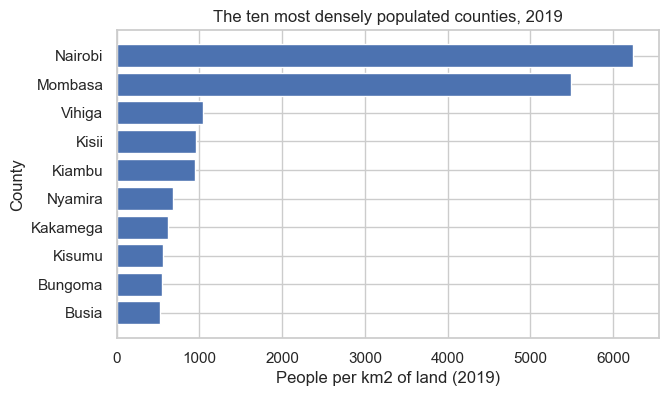

In [44]:
# plot the ten densest counties
top = pop19.sort_values("pop_density", ascending=False).head(10)
plt.figure(figsize=(7, 4))
plt.barh(top["county"][::-1], top["pop_density"][::-1])
plt.xlabel("People per km2 of land (2019)")
plt.ylabel("County")
plt.title("The ten most densely populated counties, 2019")
plt.show()

**Observation:** Nairobi (about 6,250) and Mombasa (about 5,500) are far ahead of everyone. The third county, Vihiga, has about 1,000 people per km2, and the tenth, Busia, about 500. After the two cities the densest counties are mostly in western Kenya, plus Kiambu.

### 3.5 Put the static columns together

In [45]:
# merge terrain, land cover, rivers and population density on pcode (one row per county)
static = srtm.merge(wc, on="pcode", validate="one_to_one")
static = static.merge(prox, on="pcode", validate="one_to_one")
static = static.merge(density, on="pcode", validate="one_to_one")
print(static.shape, "| missing:", static.isna().sum().sum(), "| unique pcodes:", static["pcode"].is_unique)
print(static.columns.tolist())

(47, 21) | missing: 0 | unique pcodes: True
['pcode', 'elevation', 'elev_std', 'slope', 'pct_flat', 'area_km2', 'lc_tree', 'lc_shrub', 'lc_grass', 'lc_crop', 'lc_built', 'lc_bare', 'lc_water', 'lc_wetland', 'lc_mangrove', 'pct_within_1km_river', 'pct_within_5km_river', 'pct_within_1km_water', 'pct_water', 'pct_occasional_water', 'pop_density']


**Observation:** The static table has 47 rows and 21 columns (`pcode` and 20 features) with no missing values and one row per county.

In [46]:
# compare with the pipeline's data/interim/static_county.csv
pipe = pd.read_csv("../../data/interim/static_county.csv", dtype={"pcode": str})
print("same columns:", static.columns.tolist() == pipe.columns.tolist())
both = static.merge(pipe, on="pcode", suffixes=("", "_pipe"))
diffs = {c: (both[c] - both[c + "_pipe"]).abs().max() for c in static.columns if c != "pcode"}
print("rows matched:", len(both), "| largest difference over all columns:", max(diffs.values()))

same columns: True
rows matched: 47 | largest difference over all columns: 0.0


**Observation:** The static table has the same columns, in the same order, as the pipeline's `static_county.csv`. All 47 rows match with a largest difference of 0.0.

## 4. Built-up share by month (GHSL)

GHSL maps the built-up surface every five years: 2000, 2005, ..., 2025. We want a value for every month, so we draw a straight line between two neighbouring anchors. The anchors sit on 1 January of their year, which is month 0, 60, 120, 180, 240 and 300 counted from January 2000. After the last anchor (January 2025) we keep the value flat until December 2025.

In [47]:
# load the five-yearly built-up share
ghsl = pd.read_csv("../../data/raw/earth_engine/ghsl_builtup_county_5yr_cod.csv", dtype={"pcode": str})
ghsl = ghsl[["pcode", "year", "pct_built"]]
print(ghsl.shape, "| years:", sorted(ghsl["year"].unique().tolist()), "| missing:", ghsl["pct_built"].isna().sum())
ghsl[ghsl["pcode"] == "KE042"]

(282, 3) | years: [2000, 2005, 2010, 2015, 2020, 2025] | missing: 0


,pcode,year,pct_built
41,KE042,2000,0.012987
88,KE042,2005,0.015914
135,KE042,2010,0.021423
182,KE042,2015,0.029835
229,KE042,2020,0.042745
276,KE042,2025,0.048027


**Observation:** The file has 282 rows (47 counties x 6 anchor years) and no missing values. For Kisumu the built-up share grows from 0.0130 in 2000 to 0.0160, 0.0214, 0.0298, 0.0427 and 0.0480 in 2025, which is about 3.7 times in 25 years.

In [48]:
# worked example: Kisumu in April 2024
anchors = [0, 60, 120, 180, 240, 300]
t = (2024 - 2000) * 12 + (4 - 1)
v2020 = ghsl[(ghsl["pcode"] == "KE042") & (ghsl["year"] == 2020)]["pct_built"].iloc[0]
v2025 = ghsl[(ghsl["pcode"] == "KE042") & (ghsl["year"] == 2025)]["pct_built"].iloc[0]
w = (t - 240) / (300 - 240)
print("months since January 2000:", t)
print("share of the way from 2020 to 2025:", w)
print("pct_built 2020:", round(v2020, 4), "| 2025:", round(v2025, 4))
print("interpolated April 2024:", round(v2020 + w * (v2025 - v2020), 4))

months since January 2000: 291
share of the way from 2020 to 2025: 0.85
pct_built 2020: 0.0427 | 2025: 0.048
interpolated April 2024: 0.0472


**Observation:** April 2024 is month 291 from January 2000. That is 85% of the way from 2020 (month 240) to 2025 (month 300). So 0.0427 + 0.85 x (0.0480 - 0.0427) = 0.0472, which is the value quoted for Kisumu.

In [49]:
# interpolate every county for every month of the grid
grid["t"] = (grid["year"] - 2000) * 12 + grid["month"] - 1
grid["pct_built"] = np.nan
for pc, gg in ghsl.groupby("pcode"):
    gg = gg.sort_values("year")
    rows = grid["pcode"] == pc
    grid.loc[rows, "pct_built"] = np.interp(grid.loc[rows, "t"], anchors, gg["pct_built"].to_numpy())
print("missing pct_built:", grid["pct_built"].isna().sum())
print("Kisumu April 2024:", round(grid[(grid["pcode"] == "KE042") & (grid["year"] == 2024) & (grid["month"] == 4)]["pct_built"].iloc[0], 4))
print("Kisumu Jan 2025 and Dec 2025:", grid[(grid["pcode"] == "KE042") & (grid["year"] == 2025) & (grid["month"].isin([1, 12]))]["pct_built"].round(4).tolist())

missing pct_built: 0
Kisumu April 2024: 0.0472
Kisumu Jan 2025 and Dec 2025: [0.048, 0.048]


**Observation:** All 14,664 rows have a `pct_built` value (0 missing). Kisumu April 2024 is 0.0472, as in the hand calculation. January and December 2025 are both 0.048, so the last anchor is held flat for the whole of 2025.

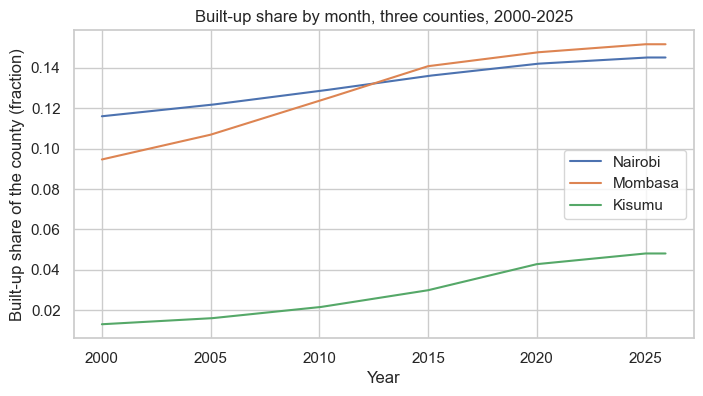

In [50]:
# plot pct_built for three counties
plt.figure(figsize=(8, 4))
for pc, name in [("KE047", "Nairobi"), ("KE001", "Mombasa"), ("KE042", "Kisumu")]:
    one = grid[grid["pcode"] == pc]
    plt.plot(one["year"] + (one["month"] - 1) / 12, one["pct_built"], label=name)
plt.xlabel("Year")
plt.ylabel("Built-up share of the county (fraction)")
plt.title("Built-up share by month, three counties, 2000-2025")
plt.legend()
plt.show()

**Observation:** Nairobi grows from 0.116 in 2000 to about 0.145 in 2025, Mombasa from 0.095 to about 0.152 (it passes Nairobi around 2012), and Kisumu from 0.013 to 0.048. The lines are straight between the 5-year anchors and flat in 2025, so the series are smooth. The values change slowly, which is why `pct_built` can only help to separate counties.

In [51]:
# compare with the pipeline's data/interim/slow_county_month.csv
pipe = pd.read_csv("../../data/interim/slow_county_month.csv", dtype={"pcode": str})
both = grid.merge(pipe, on=["pcode", "year", "month"], suffixes=("", "_pipe"))
print("rows matched:", len(both), "of", len(grid))
print("largest difference pct_built:", (both["pct_built"] - both["pct_built_pipe"]).abs().max())

rows matched: 14664 of 14664
largest difference pct_built: 0.0


**Observation:** All 14,664 rows match the pipeline's `slow_county_month.csv`, with a largest difference of 0.0 for `pct_built`.

## 5. Join and save

In [52]:
# join the county-month columns onto the grid (the row count must stay 14,664)
out = grid[["pcode", "year", "month"]].merge(era_out, on=["pcode", "year", "month"], how="left", validate="one_to_one")
print("rows after ERA5 merge:", len(out))
out = out.merge(glo_out, on=["pcode", "year", "month"], how="left", validate="one_to_one")
print("rows after GloFAS merge:", len(out))
out = out.merge(grid[["pcode", "year", "month", "pct_built"]], on=["pcode", "year", "month"], how="left", validate="one_to_one")
print("rows after built-up merge:", len(out))
print(out.shape)

rows after ERA5 merge:

 14664
rows after GloFAS merge: 14664
rows after built-up merge: 14664
(14664, 11)


**Observation:** Each of the three left merges keeps 14,664 rows. The result has 11 columns: 3 keys and 8 features (4 soil columns, `runoff_rank`, 2 discharge columns and `pct_built`).

In [53]:
# missing values per column, then save both files
print("missing values:", out.isna().sum().sum())
out.to_csv("../../data/interim/nb_soil_rivers.csv", index=False)
static.to_csv("../../data/interim/nb_static_county.csv", index=False)
print("saved nb_soil_rivers.csv", out.shape, "and nb_static_county.csv", static.shape)

missing values: 0
saved nb_soil_rivers.csv (14664, 11) and nb_static_county.csv (47, 21)


**Observation:** There are no missing values at all in the two result tables. We saved `data/interim/nb_soil_rivers.csv` (14,664 x 11) and `data/interim/nb_static_county.csv` (47 x 21).

## Summary

- **Soil and runoff (ERA5-Land):** two soil layers with a 1-month lag, and runoff turned into `runoff_rank`, a within-county percentile against 2000-2019, because the raw runoff is not comparable with CHIRPS rain.
- **River discharge (GloFAS):** daily values are dated by `valid_time - 1 day`, reduced to the largest cell inside each county per month, and turned into `discharge_rank` and its lag against 2000-2019.
- **Static features:** terrain, land cover (shares add to 1), five river and water shares (the two distance columns are dropped) and `pop_density` (2019 census population over KNBS land area) are one value per county.
- **Built-up share:** `pct_built` is interpolated linearly between the five-yearly anchors and held flat for 2025.
- All results match the pipeline's own files. Saved: `data/interim/nb_soil_rivers.csv` (14,664 rows) and `data/interim/nb_static_county.csv` (47 rows). Notebook 04 adds the flood labels and builds the final table.